# LAB. 2 - Selecting the best hyperparameter value with Cross-Validation

In this lab we apply cross-validation to select the best value of the hyperparameter K in KNN. To this purpose, we suggest you use the following datasets we already collected for you (see folder Material):

  - (Training1, Test1): n=70, no noise, suggested K values are in the range 1 ... 13
  - (Training2, Test2): n=40, no noise, suggested K values are in the range 1 ... 23
  - (Training3, Test3): n=200, 20% flipped labels, suggested K values are in the range 1 ... 31
  - (Training4, Test4): n=200, 5% flipped labels, suggested K values are in the range 1 ... 19

Note that each dataset includes both a training and a test set. You **cannot use the test set to choose k**: you should assume you don't have access to the test set when doing model selection!

To load a dataset use function
`Xtr, Ytr, Xte, Yte = load_dataset(path_tr, path_te)`

Where:
- **_path\_tr_**: is the path to the file which contains the training set
- **_path\_te_**: is the path to the file which contains the test set

and it returns:
- **_Xtr_**: Inputs of training set
- **_Ytr_**: Outputs of training set
- **_Xte_**: Inputs of test set
- **_Yte_**: Outputs of test set

In [24]:
from __future__ import annotations
# Packages used
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from numpy.random import Generator
import pickle


def _check_random_generator(rng: int | Generator | None) -> Generator:
    """Convert rng into a np.random.Generator instance."""
    if rng is None:
        print("⚠️  Warning: Set the `rng` parameter to a NumPy random generator\n"
              "   (e.g. `np.random.default_rng(42)`) or specify a fixed seed to ensure\n"
              "   your results are reproducible. Proceeding with a random seed for now.")
        return np.random.default_rng()
    if isinstance(rng, np.random.Generator):
        return rng
    if isinstance(rng, (int, np.integer)):
        return np.random.default_rng(rng)

In [25]:
# This is the utility function to load the dataset
def load_dataset(path_tr, path_te):
    with open(path_tr,"rb") as f:
        [Xtr, Ytr] = pickle.load(f)
    with open(path_te,"rb") as f:
        [Xte, Yte] = pickle.load(f)
    return Xtr, Ytr, Xte, Yte

### K-NN algorithm [functions from past LAB1]

In [26]:
def euclidDistance(P1,P2):
    return np.linalg.norm(P1-P2,2)

In [27]:
def allDistances(X1, X2):
    D = np.zeros((X1.shape[0], X2.shape[0]))
    for i in range(X1.shape[0]):
        for j in range(X2.shape[0]):
            D[i, j] = euclidDistance(X1[i], X2[j])
    return D

In [28]:
def kNNClassify(Xtr, Ytr, k, Xte):
    n_train = Xtr.shape[0]
    n_test = Xte.shape[0]
    if np.any(np.abs(Ytr) != 1):
        raise ValueError("The values of Ytr should be +1 or -1.")
    if k < 1:
        raise ValueError("k must be positive")
    if k > n_train:
        print("k is greater than the number of points, setting k=n_train")
        k = n_train
    Ypred = np.zeros(n_test)
    dist = allDistances(Xte, Xtr)
    for idx in range(n_test):
        nearest = np.argsort(dist[idx])[:k]
        vote = np.sum(Ytr[nearest])
        Ypred[idx] = 1 if vote >= 0 else -1  # tie-breaking: +1
    return Ypred


In [40]:
def separatingFkNN(Xtr, Ytr, k, Xte, Yte):
    x1min, x1max = min(Xtr[:, 0]), max(Xtr[:, 0])
    x2min, x2max = min(Xtr[:, 1]), max(Xtr[:, 1])

    # Number of mesh points for visualization
    Nx1, Nx2 = 100, 100
    x1mesh = np.linspace(x1min, x1max, Nx1)
    x2mesh = np.linspace(x2min, x2max, Nx2)

    # Create mesh and reshape x1 and x2 into a single array of points
    x1, x2 = np.meshgrid(x1mesh, x2mesh)
    meshpoints = np.column_stack((x1.ravel(), x2.ravel()))

    # Run kNN classifier on mesh points
    ypred = kNNClassify(Xtr, Ytr, k, meshpoints)

    plt.subplots()
    plt.contour(x1mesh, x2mesh, np.reshape(ypred, (Nx2, Nx1)), levels=[0])

    # Optionally plot training data
    plt.scatter(Xtr[:, 0], Xtr[:, 1], c=Ytr, marker='x', s=50, zorder=10, alpha=0.8)

    # Plot test points
    plt.scatter(Xte[Yte==1, 0], Xte[Yte==1, 1], c="#C59434", marker='o', s=50, zorder=10, alpha=0.8)
    plt.scatter(Xte[Yte==-1, 0], Xte[Yte==-1, 1], c="#092C48", marker='o', s=50, zorder=10, alpha=0.8)

    plt.xlim(x1min, x1max)
    plt.ylim(x2min, x2max)
    plt.title(f"Separating function, k={k}")
    plt.show()

In [30]:
def calcError(Ypred, Ytrue):
    return (np.count_nonzero(Ypred != Ytrue)) / len(Ytrue)

### K-Fold cross validation

In K-Fold cross validation, the data are split into K parts of approximately equal size, and K different models are trained each time leaving out one of the parts of data. Then the estimate for the test error is the mean of the error of the K different models.

In [31]:
def KFoldCVkNN(Xtr, Ytr, num_folds, k_list, rng: int | Generator | None = None):
    """Run K-Fold CV for the kNN model
    
    Parameters:
    -----------
     - Xtr : np.array
         the full training set data
     - Ytr : np.array
         the full training set labels
     - num_folds : int
         the number of folds
     - k_list : List[int]
         the values of k (for k-NN) to try
     - rng : Optional[int | Generator | None]
         optional random state

    Returns:
    --------
     - best_k : int
         The value of k (in k_list) which obtains the best average validation error
     - best_k_idx : int
         The index of the best_k element in k_list
     - tr_err_mean : np.array
         A 1D array of the same length as k_list, with the average training error for each tested k.
     - tr_err_std : np.array
         A 1D array of the same length as k_list, with the standard deviation 
         of the training error for each tested k.
     - val_err_mean : np.array
         A 1D array of the same length as k_list, with the average validation error for each tested k.
     - val_err_std : np.array
         A 1D array of the same length as k_list, with the standard deviation
         of the validation error for each tested k.
    """
    rng = _check_random_generator(rng)
    # Ensures that k_list is a numpy array
    k_list = np.array(k_list)
    num_k = len(k_list)

    n_tot = Xtr.shape[0]

    # We want to compute 1 error for each `k` and each fold
    tr_errors = np.zeros((num_k, num_folds))
    val_errors = np.zeros((num_k, num_folds))

    # `split_idx`: a list of arrays, each containing the validation indices for 1 fold
    rand_idx = rng.choice(n_tot, size=n_tot, replace=False)
    split_idx = np.array_split(rand_idx, num_folds)
    
    for fold_idx in range(num_folds):
        # Set the indices in boolean mask for all validation samples to `True`
        val_mask = np.zeros(n_tot, dtype=bool)
        val_mask[split_idx[fold_idx]] = True
        # Split training set in training part and validation part
        # Hint: you can use boolean mask as index vector to split Xtr and Ytr
        x_train = Xtr[val_mask==False]
        y_train = Ytr[val_mask==False]
        x_val = Xtr[val_mask==True]
        y_val = Ytr[val_mask==True]
        
        for k_idx, current_k in enumerate(k_list):
            # TODO: Compute the training error of the kNN classifier for the given value of k
            # ... write your code here ...
            # TODO: Compute the validation error of the kNN classifier for the given value of k
             # ... write your code here ...
            
    # Calculate error statistics along the repetitions:
    # 1) mean training error, training error standard deviation
    tr_err_mean = np.mean(tr_errors, axis=1)
    tr_err_std = np.std(tr_errors, axis=1)
    # 2) mean validation error, validation error standard deviation
    val_err_mean = np.mean(val_errors, axis=1)
    val_err_std = np.std(val_errors, axis=1)
    # 3) best k (k which minimize mean validation error) and index of best k in k_list
    best_k = k_list[np.argmin(val_err_mean)]
    best_k_idx = int(np.argmin(val_err_mean))
    
    return best_k, best_k_idx, tr_err_mean, tr_err_std, val_err_mean, val_err_std

### Now we call the K-Fold Cross Validation on one of the dataset, for instance the first one

In [32]:

Xtr, Ytr, Xte, Yte = load_dataset(
    "./Material/Classification/Training1.dat", "./Material/Classification/Test1.dat")

num_folds = 5
k_list = range(1, 13, 2)
best_k, best_k_idx, tr_err_mean, tr_err_std, val_err_mean, val_err_std = KFoldCVkNN(
    Xtr, Ytr, num_folds, k_list, rng=42)

print(f"The best k chosen with {num_folds} folds is {best_k} with error "
      f"{np.min(val_err_mean) * 100:.2f} +- {val_err_std[np.argmin(val_err_mean)] * 100:.2f}%")


The best k chosen with 5 folds is 1 with error 1.43 +- 2.86%


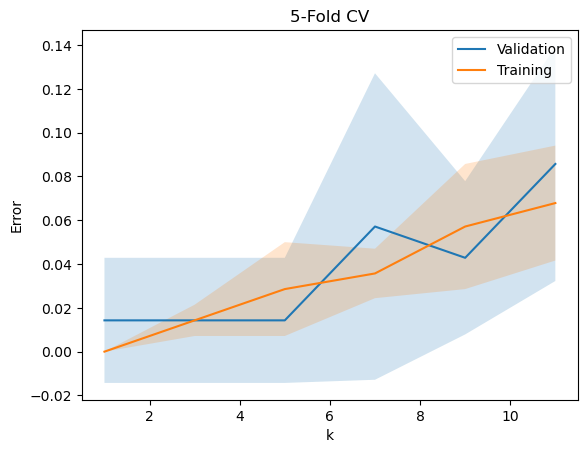

In [33]:
# We plot the training e validation error
fig, ax = plt.subplots()
ax.plot(k_list, val_err_mean, label="Validation")
ax.fill_between(k_list, val_err_mean - val_err_std, val_err_mean + val_err_std, alpha=0.2)
ax.plot(k_list, tr_err_mean, label="Training")
ax.fill_between(k_list, tr_err_mean - tr_err_std, tr_err_mean + tr_err_std, alpha=0.2)

ax.set_title(f"{num_folds}-Fold CV")
ax.set_ylabel("Error")
ax.set_xlabel("k")
ax.legend();

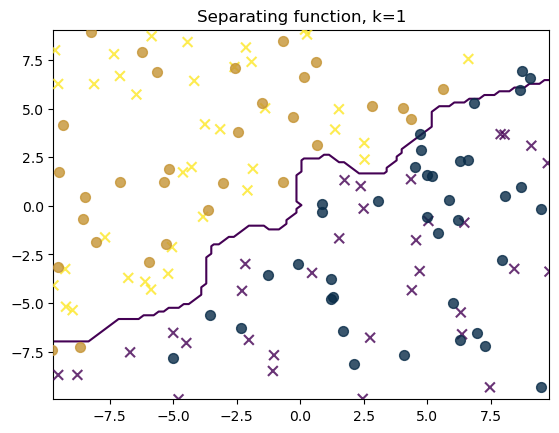

In [41]:
# We also plot the separating curve
separatingFkNN(Xtr, Ytr, best_k, Xte, Yte)

In [34]:
# Finally, evaluate the model with the best k on the test set now

# ... write your code here ...

print(f"The test error with the best k ({best_k}) is: {te_err*100:.3f}%")

The test error with the best k (1) is: 7.143%


### Cross validation and Noise in k-NN

In this final task we consider the effect of noise on the best k (chosen with k-fold CV).

We will use dataset3 which has high noise (20%), and dataset4 which has low noise (5%).

You will have to do the following:
 1. Use k-fold CV to find the best k for datasets 3 and 4.
 2. Compare the obtained values of k, with the actual best k on the test error of the two datasets. This should be a sanity check: if the errors on k-fold CV and on the test set are very different, something may be wrong with your code.
 3. Comment on how noise affects the best k: does a more noisy dataset need a higher or a lower k, and why? It may be useful to plot the separating function (using the `separatingFkNN` function) of k-NN with the best k for the two datasets.

Dataset 3: CV best k=17, CV error=0.210, test error at CV k=0.215, test-optimal k (diagnostic)=11


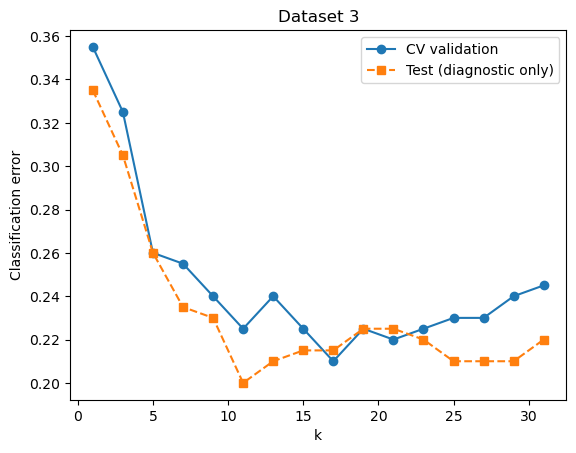

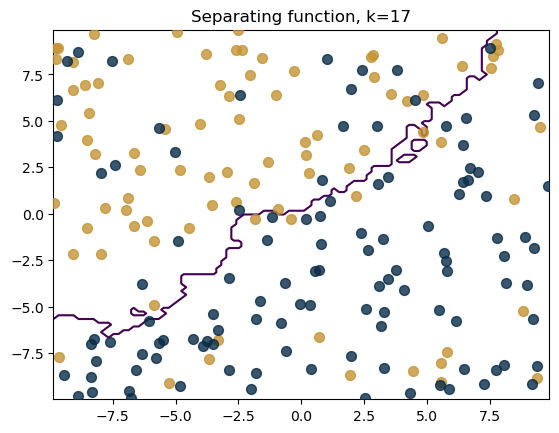

Dataset 4: CV best k=5, CV error=0.065, test error at CV k=0.065, test-optimal k (diagnostic)=5


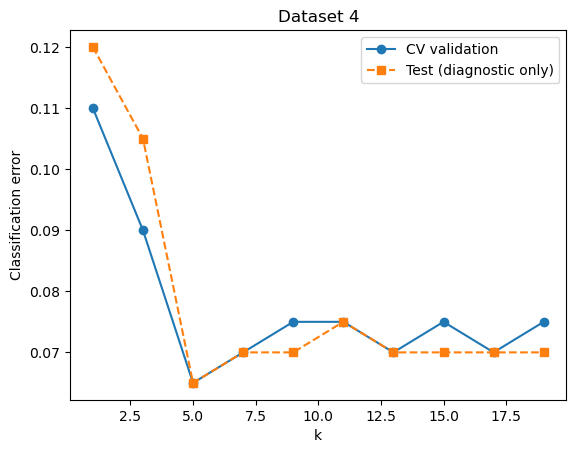

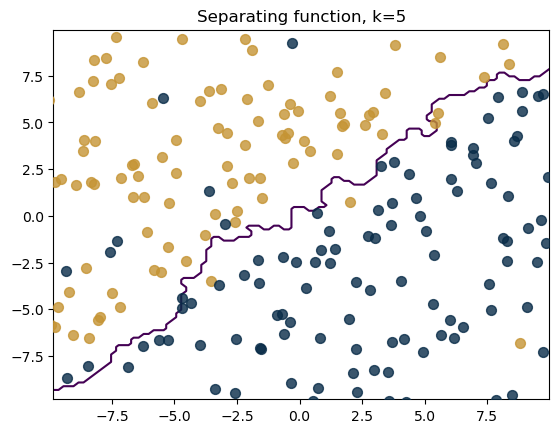

In [22]:
# The external Material/Classification files must be available to run this cell.
for dataset_id, max_k in [(3, 31), (4, 19)]:
    Xtr, Ytr, Xte, Yte = load_dataset(
        f'./Material/Classification/Training{dataset_id}.dat',
        f'./Material/Classification/Test{dataset_id}.dat')
    k_list = list(range(1, max_k + 1, 2))
    
    # Call cross-validation 
    # ... write your code here ...
    
    # Test errors below are computed ONLY after CV-based selection.
    
    test_errors = np.array([
        calcError(kNNClassify(Xtr, Ytr, k, Xte), Yte) for k in k_list
    ])
    oracle_idx = int(np.argmin(test_errors))  # diagnostic only; never use for selection
    print(f'Dataset {dataset_id}: CV best k={best_k}, '
          f'CV error={val_mean[best_idx]:.3f}, '
          f'test error at CV k={test_errors[best_idx]:.3f}, '
          f'test-optimal k (diagnostic)={k_list[oracle_idx]}')
    plt.figure()
    plt.plot(k_list, val_mean, 'o-', label='CV validation')
    plt.plot(k_list, test_errors, 's--', label='Test (diagnostic only)')
    plt.xlabel('k'); plt.ylabel('Classification error')
    plt.title(f'Dataset {dataset_id}'); plt.legend(); plt.show()
    separatingFkNN(Xtr, Ytr, best_k, Xte, Yte)
